In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.optimization import (annual_inputs, min_variance, max_sharpe,
                              efficient_frontier, steepest_descent_min_var, RF_LOG)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

returns = pd.read_csv(config.PROCESSED_DIR / "returns_stocks.csv", index_col=0, parse_dates=True)
train = returns.loc[config.TRAIN_START:config.TRAIN_END]       # optimizer only sees this
mu, cov = annual_inputs(train)
mu_v, cov_v = mu.values, cov.values
n = len(mu)

w_mv = min_variance(cov_v)
w_ms = max_sharpe(mu_v, cov_v)
w_eq = np.full(n, 1 / n)

def summarize(name, w):
    ret, vol = w @ mu_v, np.sqrt(w @ cov_v @ w)
    return {"portfolio": name, "return": ret, "volatility": vol,
            "sharpe": (ret - RF_LOG) / vol,
            "stocks_over_1pct": int((w > 0.01).sum()), "max_weight": w.max()}

table = pd.DataFrame([summarize("Equal weight", w_eq),
                      summarize("Min variance", w_mv),
                      summarize("Max Sharpe", w_ms)]).set_index("portfolio")
print("Training window:", train.index.min().date(), "to", train.index.max().date())
table.round(3)

Training window: 2019-01-01 to 2022-12-30


,return,volatility,sharpe,stocks_over_1pct,max_weight
portfolio,,,,,
Equal weight,0.161,0.200,0.491,30,0.033
Min variance,0.143,0.157,0.512,12,0.139
Max Sharpe,0.221,0.185,0.856,9,0.150


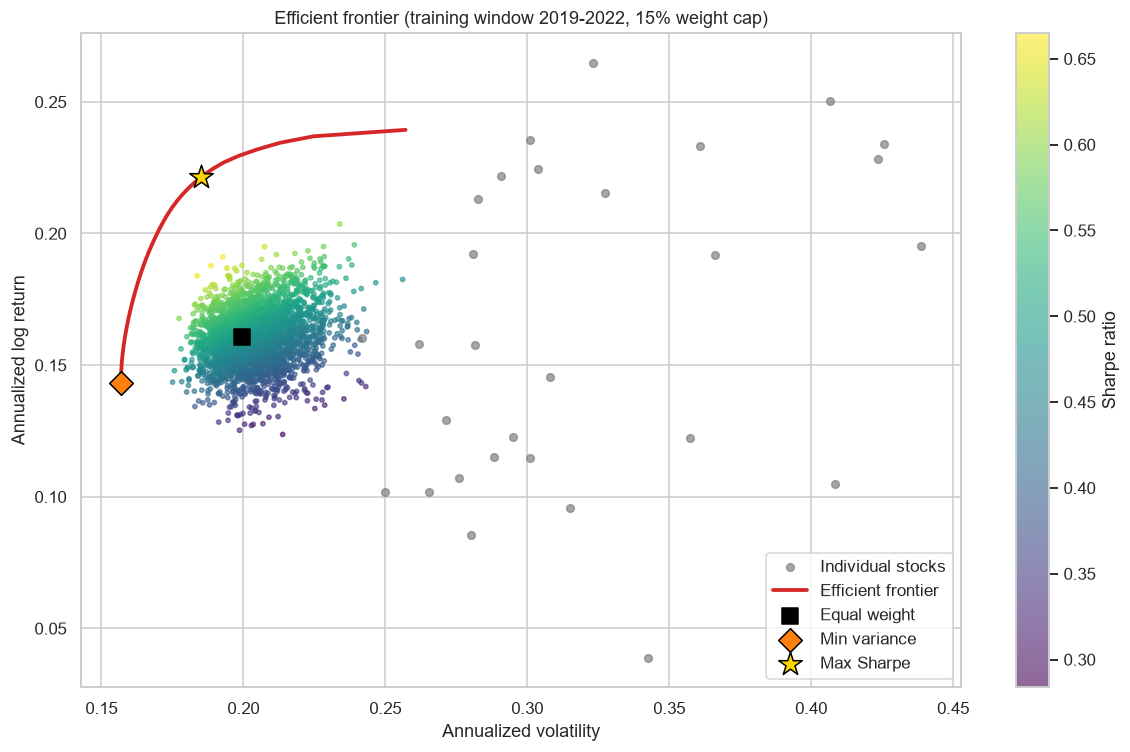

In [2]:
rng = np.random.default_rng(42)
rand_w = rng.dirichlet(np.ones(n), 3000)                       # 3000 random portfolios
rand_ret = rand_w @ mu_v
rand_vol = np.sqrt(np.einsum("ij,jk,ik->i", rand_w, cov_v, rand_w))
rand_sharpe = (rand_ret - RF_LOG) / rand_vol

frontier = efficient_frontier(mu_v, cov_v)

plt.figure(figsize=(11, 7))
sc = plt.scatter(rand_vol, rand_ret, c=rand_sharpe, cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, label="Sharpe ratio")
plt.scatter(np.sqrt(np.diag(cov_v)), mu_v, color="grey", s=25, alpha=0.7, label="Individual stocks")
plt.plot(frontier["volatility"], frontier["target_return"], color="#d62728", lw=2.5, label="Efficient frontier")
for name, w, marker, color in [("Equal weight", w_eq, "s", "black"),
                               ("Min variance", w_mv, "D", "#ff7f0e"),
                               ("Max Sharpe", w_ms, "*", "gold")]:
    plt.scatter(np.sqrt(w @ cov_v @ w), w @ mu_v, marker=marker, s=260 if marker == "*" else 120,
                color=color, edgecolor="black", zorder=5, label=name)
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized log return")
plt.title("Efficient frontier (training window 2019-2022, 15% weight cap)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "10_efficient_frontier.png", dpi=200, bbox_inches="tight")
plt.show()

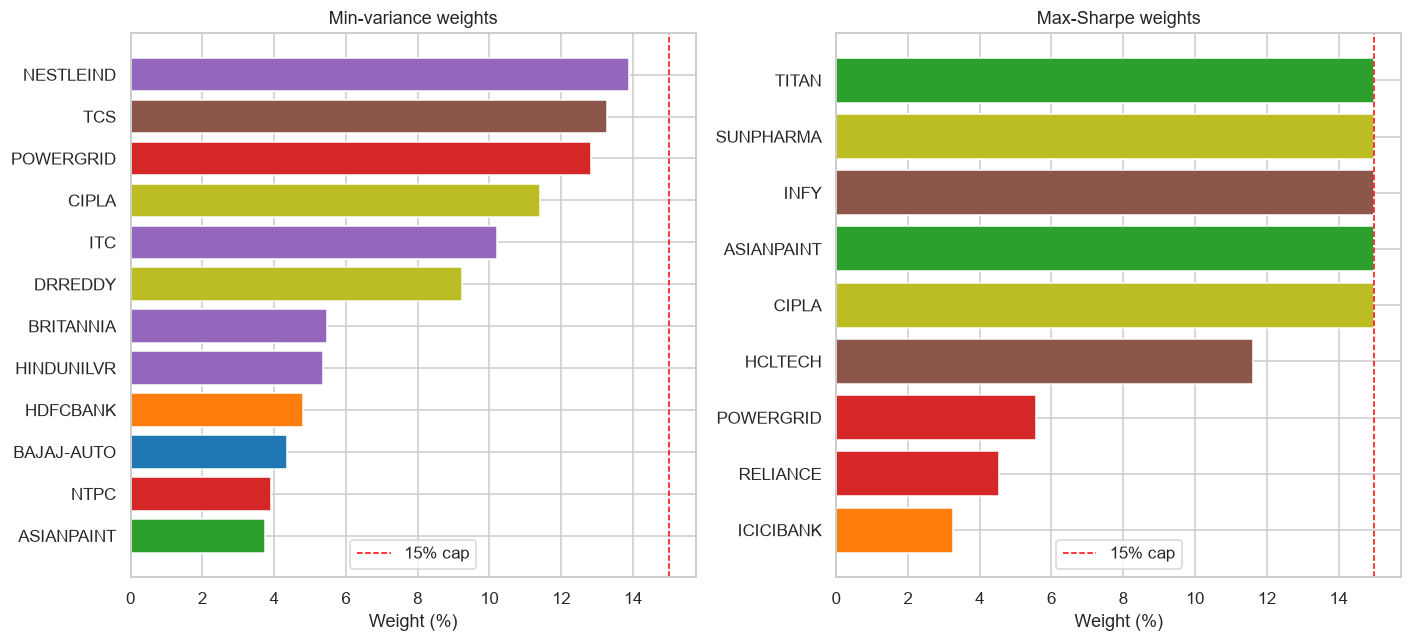

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
for ax, (title, w) in zip(axes, [("Min-variance weights", w_mv), ("Max-Sharpe weights", w_ms)]):
    s = pd.Series(w, index=returns.columns)
    s = s[s > 0.01].sort_values()
    colors = [sns.color_palette("tab10", 9)[sorted(set(config.SECTOR_MAP.values())).index(config.SECTOR_MAP[t])]
              for t in s.index]
    ax.barh([t.replace(".NS", "") for t in s.index], s.values * 100, color=colors)
    ax.axvline(15, color="red", ls="--", lw=1, label="15% cap")
    ax.set_title(title); ax.set_xlabel("Weight (%)"); ax.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "11_optimal_weights.png", dpi=200, bbox_inches="tight")
plt.show()

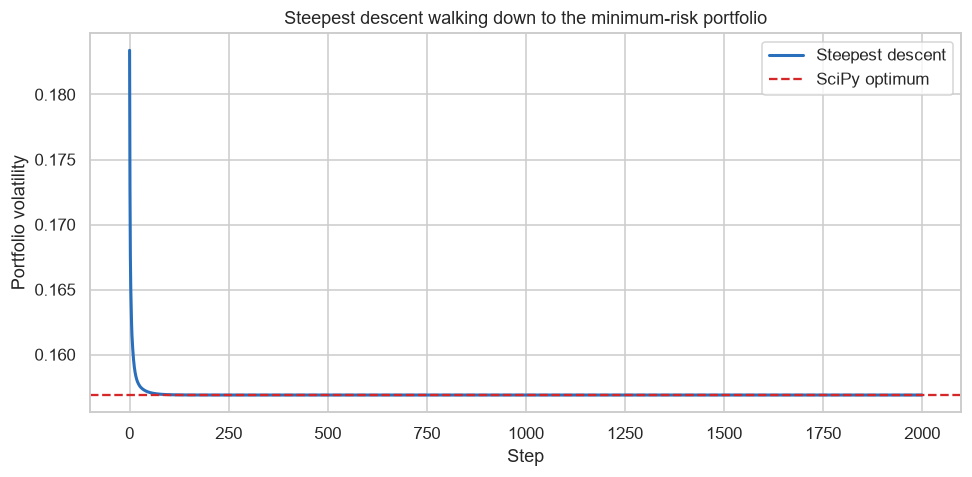

Steepest descent volatility: 0.1569
SciPy volatility:            0.1569


In [4]:
w_sd, history = steepest_descent_min_var(cov_v, steps=2000)
w_mv_free = min_variance(cov_v, cap=1.0)                       # same rules but no 15% cap
best_var = w_mv_free @ cov_v @ w_mv_free

plt.figure(figsize=(9, 4.5))
plt.plot(np.sqrt(history), color="#2a6fbb", lw=2, label="Steepest descent")
plt.axhline(np.sqrt(best_var), color="#d62728", ls="--", label="SciPy optimum")
plt.xlabel("Step"); plt.ylabel("Portfolio volatility")
plt.title("Steepest descent walking down to the minimum-risk portfolio")
plt.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "12_steepest_descent.png", dpi=200, bbox_inches="tight")
plt.show()
print("Steepest descent volatility:", round(float(np.sqrt(history[-1])), 4))
print("SciPy volatility:           ", round(float(np.sqrt(best_var)), 4))

In [5]:
weights = pd.DataFrame({"ticker": returns.columns,
                        "sector": returns.columns.map(config.SECTOR_MAP),
                        "equal_weight": w_eq, "min_variance": w_mv, "max_sharpe": w_ms})
weights.to_csv(config.PROCESSED_DIR / "weights_train.csv", index=False)   # used by backtest
weights.to_csv(config.POWERBI_DIR / "optimal_weights.csv", index=False)
frontier.to_csv(config.POWERBI_DIR / "efficient_frontier.csv", index=False)
table.rename_axis("portfolio").reset_index().to_csv(config.POWERBI_DIR / "portfolio_summary_train.csv", index=False)

sector_w = weights.groupby("sector")[["min_variance", "max_sharpe"]].sum()
print("Top sector, min variance:", sector_w["min_variance"].idxmax(), round(sector_w["min_variance"].max(), 3))
print("Top sector, max Sharpe:  ", sector_w["max_sharpe"].idxmax(), round(sector_w["max_sharpe"].max(), 3))
print("Top 3 stocks, max Sharpe:", list(weights.set_index("ticker")["max_sharpe"].nlargest(3).index))
print("Stocks hitting the 15% cap (max Sharpe):", int((w_ms > 0.1499).sum()))

Top sector, min variance: FMCG 0.349
Top sector, max Sharpe:   Consumer 0.3
Top 3 stocks, max Sharpe: ['ASIANPAINT.NS', 'INFY.NS', 'SUNPHARMA.NS']
Stocks hitting the 15% cap (max Sharpe): 5


In [6]:
print("Equal-weight vol:", round(table.loc["Equal weight", "volatility"] * 100, 1), "%")
print("Min-variance vol:", round(table.loc["Min variance", "volatility"] * 100, 1), "%")
print("Equal-weight Sharpe:", round(table.loc["Equal weight", "sharpe"], 2))
print("Max-Sharpe Sharpe:", round(table.loc["Max Sharpe", "sharpe"], 2))
print("Steepest descent vol:", round(float(np.sqrt(history[-1])), 4))
print("SciPy vol:", round(float(np.sqrt(best_var)), 4))

Equal-weight vol: 20.0 %
Min-variance vol: 15.7 %
Equal-weight Sharpe: 0.49
Max-Sharpe Sharpe: 0.86
Steepest descent vol: 0.1569
SciPy vol: 0.1569


## Conclusion

On the 2019-2022 training window, the minimum-variance portfolio cuts volatility to **15.7%** from **20.0%** for equal weight, and the max-Sharpe portfolio reaches a Sharpe ratio of **0.86** versus **0.49** for equal weight.

Minimum variance is tilted toward **FMCG** (**34.9%** of the portfolio), a defensive sector with low volatility. Max Sharpe is tilted toward **Consumer** (**30.0%**) and led by **ASIANPAINT, INFY and SUNPHARMA**. **5 stocks hit the 15% cap**, so about 75% of the max-Sharpe portfolio sits in five names, meaning it is concentrated even with the cap.

A hand-written steepest descent (with projection onto valid weights) reached a volatility of **0.1569**, matching SciPy's **0.1569**, which shows the library result can be reproduced from first principles.

**Caveat:** these results are in-sample, so they are optimistic by construction. Expected returns are estimated from limited history and are noisy, and optimizers amplify that noise, which is why max Sharpe concentrates in a few winners. The next milestone tests both portfolios on 2023 onward.